# Mini-Project 1: Weather Forecast Using Python Web APIs

This project retrieves a weather forecast for a chosen location using
Open-Meteo and includes a comparison with MET Norway.

It demonstrates HTTP requests, location lookup, JSON processing,
forecast tables and charts, and handling failed requests.

Reusable functions are stored in `src/weather.py`. Saved JSON samples
support offline testing.

In [1]:
import sys

# Confirm that the notebook uses this project's Python environment.
print(sys.executable)

c:\Users\ACRAM TECH\Desktop\OOP mini project assignment\OOP-Assignment-2-Weather-and-Tax\.venv\Scripts\python.exe


## Configuration

This section sets the location and forecast length. The contact email
is read from an environment variable so personal contact details are
not stored in the shared notebook.

In [1]:
import os

# Set the location and number of forecast days.
location_name = "Kampala"
forecast_days = 5

# Read our contact email from the local environment.
contact_email = os.getenv("WEATHER_CONTACT_EMAIL", "").strip()

print("Location:", location_name)
print("Forecast days:", forecast_days)
print("Contact email configured:", bool(contact_email))

Location: Kampala
Forecast days: 5
Contact email configured: True


In [26]:
# Import tools for locating the project folder.
import sys
from pathlib import Path

# Locate the project root from either the root or notebooks folder.
project_folder = Path.cwd()
if not (project_folder / "src").is_dir():
    project_folder = project_folder.parent

if str(project_folder) not in sys.path:
    sys.path.insert(0, str(project_folder))

# Import our weather module and its custom exception.
import src.weather as weather_module
from src.weather import WeatherError

## Part A: Location lookup using urllib

This first request uses Python's standard library.
`urlencode` prepares the query parameters, and `json` converts
the API response into Python dictionaries and lists.

Source: Open-Meteo Geocoding API, using GeoNames location data.
Documentation: https://open-meteo.com/en/docs/geocoding-api

In [2]:
import json
import urllib.parse
import urllib.request

# Build the search URL using safely encoded query parameters.
geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"
search_params = {"name": location_name, "count": 5, "language": "en"}
query_string = urllib.parse.urlencode(search_params)

# Identify our application using the locally configured contact email.
request = urllib.request.Request(
    f"{geocoding_url}?{query_string}",
    headers={"User-Agent": f"WeatherAssignment/1.0 ({contact_email})"}
)

# Read the JSON response with a timeout of 15 seconds.
with urllib.request.urlopen(request, timeout=15) as response:
    location_data = json.load(response)

# Handle an absent results key and display any matching locations.
candidates = location_data.get("results", [])

if not candidates:
    print("No matching locations found.")

for number, place in enumerate(candidates, start=1):
    print(
        f"{number}. {place['name']}, "
        f"{place.get('country', 'Unknown country')} — "
        f"latitude: {place['latitude']}, "
        f"longitude: {place['longitude']}"
    )

print("Source: Open-Meteo Geocoding / GeoNames")

1. Kampala, Uganda — latitude: 0.31628, longitude: 32.58219
2. Kampala, Ivory Coast — latitude: 7.32344, longitude: -7.68519
3. Kampala, Democratic Republic of Congo — latitude: 2.30086, longitude: 30.59269
4. Kampala, Democratic Republic of Congo — latitude: -2.19509, longitude: 27.74864
5. Kampala, Zambia — latitude: -14.41129, longitude: 31.6098
Source: Open-Meteo Geocoding / GeoNames


In [3]:
import json
import urllib.parse
import urllib.request

# Build the search URL using safely encoded query parameters.
geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"
search_params = {"name": location_name, "count": 5, "language": "en"}
query_string = urllib.parse.urlencode(search_params)

# Identify our application using the locally configured contact email.
request = urllib.request.Request(
    f"{geocoding_url}?{query_string}",
    headers={"User-Agent": f"WeatherAssignment/1.0 ({contact_email})"}
)

# Read the JSON response with a timeout of 15 seconds.
with urllib.request.urlopen(request, timeout=15) as response:
    location_data = json.load(response)

# Handle an absent results key and display any matching locations.
candidates = location_data.get("results", [])

if not candidates:
    print("No matching locations found.")

for number, place in enumerate(candidates, start=1):
    print(
        f"{number}. {place['name']}, "
        f"{place.get('country', 'Unknown country')} — "
        f"latitude: {place['latitude']}, "
        f"longitude: {place['longitude']}"
    )

print("Source: Open-Meteo Geocoding / GeoNames")

1. Kampala, Uganda — latitude: 0.31628, longitude: 32.58219
2. Kampala, Ivory Coast — latitude: 7.32344, longitude: -7.68519
3. Kampala, Democratic Republic of Congo — latitude: 2.30086, longitude: 30.59269
4. Kampala, Democratic Republic of Congo — latitude: -2.19509, longitude: 27.74864
5. Kampala, Zambia — latitude: -14.41129, longitude: 31.6098
Source: Open-Meteo Geocoding / GeoNames


In [4]:
import time
import requests

# Measure the request duration, including downloading the response.
start_time = time.perf_counter()

# Send the same search parameters using requests.
response = requests.get(
    geocoding_url,
    params=search_params,
    headers={"User-Agent": f"WeatherAssignment/1.0 ({contact_email})"},
    timeout=15
)
response_time = time.perf_counter() - start_time

# Raise an error for an unsuccessful HTTP status.
response.raise_for_status()
requests_data = response.json()

# Inspect the HTTP response and count the matching locations.
print("Status code:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))
print(f"Response time: {response_time:.3f} seconds")
print("Matching locations:", len(requests_data.get("results", [])))
print("Source: Open-Meteo Geocoding / GeoNames")

Status code: 200
Content-Type: application/json; charset=utf-8
Response time: 0.839 seconds
Matching locations: 5
Source: Open-Meteo Geocoding / GeoNames


### Comparing urllib and requests

Both approaches returned five candidate locations for Kampala.

The urllib approach uses Python's standard library, so no additional
package is needed. We explicitly construct the query string with
urlencode, create a Request object for the headers, and parse the
response using json.load.

The requests approach is shorter. Its params argument handles query
encoding, its headers argument sets request headers, and its json()
method parses the response. Both approaches allow control over
headers and query parameters.

For HTTP errors, urllib normally raises HTTPError automatically.
With requests, we explicitly call raise_for_status() to raise an
exception for an unsuccessful HTTP status. Both requests use a
timeout, but neither demonstration yet includes retries.

### Interpreting the response

The recorded request returned status 200, indicating HTTP success.
The Content-Type was application/json; charset=utf-8, identifying
the response format and character encoding.

The measured response time was approximately 0.839 seconds.
This measures the request and response download, excluding the
subsequent JSON parsing. Timing varies with network and server
conditions; one measurement cannot establish which approach is faster.

Multiple matches show why the program must let the user select
the intended location before retrieving a forecast.

In [5]:
import sys
from pathlib import Path

# Locate the project folder when running from notebooks or the project root.
project_folder = Path.cwd()
if not (project_folder / "src").is_dir():
    project_folder = project_folder.parent

# Allow Python to import our reusable module.
if str(project_folder) not in sys.path:
    sys.path.insert(0, str(project_folder))

from src.weather import request_json

# Look up the configured location using our request function.
checked_locations = request_json(
    url=geocoding_url,
    params=search_params,
    contact_email=contact_email
)

print("Matching locations:", len(checked_locations.get("results", [])))
print("Source: Open-Meteo Geocoding / GeoNames")

Matching locations: 5
Source: Open-Meteo Geocoding / GeoNames


## Part B: Finding and selecting a location

The geocode function returns candidate locations. We display their
country, administrative area and coordinates to distinguish places
with the same name.

In [7]:
# Import tools for reloading and accessing our weather module.
import importlib
import src.weather as weather_module

# Reload the module to make the newly added function available.
importlib.reload(weather_module)

# Find locations matching the name in our configuration cell.
candidates = weather_module.geocode(location_name)

# Choose the numbered location from the displayed candidate list.
location_choice = 1

# Display enough detail to distinguish locations with the same name.
if not candidates:
    print("No matching locations. Update location_name and try again.")

for number, place in enumerate(candidates, start=1):
    print(
        f"{number}. {place['name']} | "
        f"{place.get('admin1', 'Area not provided')} | "
        f"{place.get('country', 'Country not provided')} | "
        f"Latitude: {place['latitude']}, "
        f"Longitude: {place['longitude']}"
    )

print("Source: Open-Meteo Geocoding / GeoNames")

1. Kampala | Central Region | Uganda | Latitude: 0.31628, Longitude: 32.58219
2. Kampala | Montagnes | Ivory Coast | Latitude: 7.32344, Longitude: -7.68519
3. Kampala | Ituri | Democratic Republic of Congo | Latitude: 2.30086, Longitude: 30.59269
4. Kampala | South Kivu | Democratic Republic of Congo | Latitude: -2.19509, Longitude: 27.74864
5. Kampala | Eastern Province | Zambia | Latitude: -14.41129, Longitude: 31.6098
Source: Open-Meteo Geocoding / GeoNames


In [8]:
# Check that the configured choice refers to an available location.
if not candidates:
    raise weather_module.WeatherError(
        "No locations found. Update location_name in the configuration."
    )

if (
    type(location_choice) is not int
    or not 1 <= location_choice <= len(candidates)
):
    raise weather_module.WeatherError(
        f"Choose a location number between 1 and {len(candidates)}."
    )

# Convert the displayed number to Python's zero-based list index.
selected_location = candidates[location_choice - 1]
latitude = selected_location["latitude"]
longitude = selected_location["longitude"]

# Confirm the location whose forecast we will request.
print(
    "Selected location:",
    selected_location["name"],
    selected_location.get("country", "Country not provided")
)
print("Latitude:", latitude)
print("Longitude:", longitude)

Selected location: Kampala Uganda
Latitude: 0.31628
Longitude: 32.58219


In [9]:
# Reload the module to access the new forecast function.
importlib.reload(weather_module)

# Retrieve the forecast using our selected location and configured days.
forecast_data = weather_module.get_forecast(
    latitude,
    longitude,
    forecast_days
)

# Inspect the local time zone and daily forecast measurements.
print("Time zone:", forecast_data.get("timezone"))
print("Forecast dates:", forecast_data["daily"]["time"])
print("Maximum temperatures:", forecast_data["daily"]["temperature_2m_max"])
print("Minimum temperatures:", forecast_data["daily"]["temperature_2m_min"])
print("Source: Open-Meteo — https://open-meteo.com/")

Time zone: Africa/Kampala
Forecast dates: ['2026-10-10', '2026-10-11', '2026-10-12', '2026-10-13', '2026-10-14']
Maximum temperatures: [24.7, 25.0, 25.5, 27.2, 26.7]
Minimum temperatures: [19.0, 18.4, 18.4, 17.9, 18.8]
Source: Open-Meteo — https://open-meteo.com/


In [11]:
# Reload the module to access the table conversion function.
importlib.reload(weather_module)

# Convert the saved response without making another API request.
forecast_table = weather_module.forecast_to_table(forecast_data)

# Identify the selected location and the forecast's local time zone.
print(
    f"Forecast for {selected_location['name']}, "
    f"{selected_location.get('country', 'Country not provided')}"
)
print("Time zone:", forecast_data["timezone"])

# Format measurements to one decimal place and mark missing values.
display(
    forecast_table.style.format(
        {
            "Minimum temperature (°C)": "{:.1f}",
            "Maximum temperature (°C)": "{:.1f}",
            "Precipitation (mm)": "{:.1f}",
            "Maximum wind speed (km/h)": "{:.1f}"
        },
        na_rep="Not available"
    ).hide(axis="index")
)

print("Source: Open-Meteo — https://open-meteo.com/")

Forecast for Kampala, Uganda
Time zone: Africa/Kampala


Date,Minimum temperature (°C),Maximum temperature (°C),Precipitation (mm),Maximum wind speed (km/h),Weather code,Description
2026-10-10,19.0,24.7,5.0,9.9,80,Slight rain showers
2026-10-11,18.4,25.0,15.7,13.3,95,Thunderstorm
2026-10-12,18.4,25.5,10.1,10.8,81,Moderate rain showers
2026-10-13,17.9,27.2,0.2,10.9,51,Light drizzle
2026-10-14,18.8,26.7,1.5,9.5,51,Light drizzle


Source: Open-Meteo — https://open-meteo.com/


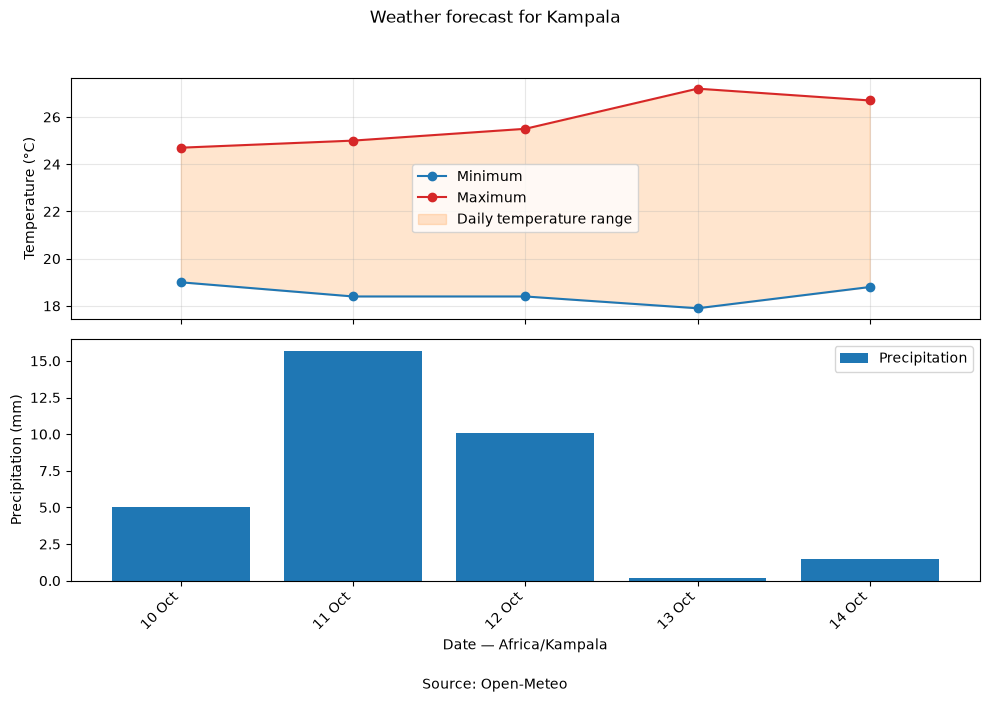

In [12]:
# Import plotting tools and pandas for handling forecast dates.
import matplotlib.pyplot as plt
import pandas as pd

# Convert the date strings into dates for the chart.
dates = pd.to_datetime(forecast_table["Date"])

# Create two panels sharing the same date axis.
fig, (temperature_axis, rain_axis) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True
)

# Show daily minimum and maximum temperatures with the range shaded.
temperature_axis.plot(
    dates,
    forecast_table["Minimum temperature (°C)"],
    marker="o",
    label="Minimum",
    color="tab:blue"
)
temperature_axis.plot(
    dates,
    forecast_table["Maximum temperature (°C)"],
    marker="o",
    label="Maximum",
    color="tab:red"
)
temperature_axis.fill_between(
    dates,
    forecast_table["Minimum temperature (°C)"],
    forecast_table["Maximum temperature (°C)"],
    color="tab:orange",
    alpha=0.2,
    label="Daily temperature range"
)
temperature_axis.set_ylabel("Temperature (°C)")
temperature_axis.legend()
temperature_axis.grid(alpha=0.3)

# Display daily precipitation totals in a separate panel.
rain_axis.bar(
    dates,
    forecast_table["Precipitation (mm)"],
    color="tab:blue",
    label="Precipitation"
)
rain_axis.set_ylabel("Precipitation (mm)")
rain_axis.set_xlabel(f"Date — {forecast_data['timezone']}")
rain_axis.set_ylim(bottom=0)
rain_axis.set_xticks(dates)
rain_axis.set_xticklabels(
    dates.dt.strftime("%d %b"), rotation=45, ha="right"
)
rain_axis.legend()

# Add the location and acknowledge the forecast provider.
fig.suptitle(f"Weather forecast for {selected_location['name']}")
fig.text(0.5, 0.01, "Source: Open-Meteo", ha="center")
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()

In [13]:
# Find the forecast's overall temperature range and precipitation total.
lowest_temperature = forecast_table["Minimum temperature (°C)"].min()
highest_temperature = forecast_table["Maximum temperature (°C)"].max()
total_precipitation = forecast_table["Precipitation (mm)"].sum(min_count=1)
strongest_wind = forecast_table["Maximum wind speed (km/h)"].max()

# Report missing measurements rather than silently treating them as zero.
measurements = forecast_table[
    [
        "Minimum temperature (°C)",
        "Maximum temperature (°C)",
        "Precipitation (mm)",
        "Maximum wind speed (km/h)"
    ]
]

if measurements.isna().any().any():
    print("The forecast has missing measurements; a full summary is unavailable.")
else:
    # Summarise the downloaded forecast in plain language.
    print(
        f"For {selected_location['name']}, from "
        f"{forecast_table['Date'].iloc[0]} to "
        f"{forecast_table['Date'].iloc[-1]}:"
    )
    print(
        f"Forecast temperatures range from {lowest_temperature:.1f}°C "
        f"to {highest_temperature:.1f}°C."
    )
    print(f"Total forecast precipitation: {total_precipitation:.1f} mm.")
    print(f"Highest daily maximum wind speed: {strongest_wind:.1f} km/h.")

print("These are forecast values, not observed weather measurements.")
print("Source: Open-Meteo — https://open-meteo.com/")

For Kampala, from 2026-10-10 to 2026-10-14:
Forecast temperatures range from 17.9°C to 27.2°C.
Total forecast precipitation: 32.5 mm.
Highest daily maximum wind speed: 13.3 km/h.
These are forecast values, not observed weather measurements.
Source: Open-Meteo — https://open-meteo.com/


In [14]:
# Import tools for saving JSON files and recording the retrieval snapshot.
import json
from datetime import datetime, timezone

# Create the sample-data folder if it does not already exist.
sample_folder = project_folder / "data"
sample_folder.mkdir(exist_ok=True)

# Preserve each sample instead of overwriting it on every notebook run.
samples = {
    "geocoding_sample.json": checked_locations,
    "forecast_sample.json": forecast_data
}

for filename, sample in samples.items():
    sample_path = sample_folder / filename

    if sample_path.exists():
        print(f"Sample already exists: {filename}")
    else:
        with sample_path.open("w", encoding="utf-8") as file:
            json.dump(sample, file, indent=2, ensure_ascii=False)
        print(f"Saved: {filename}")

# Record when the sample files were first documented.
metadata_path = sample_folder / "sample_metadata.json"

if not metadata_path.exists():
    metadata = {
        "saved_at_utc": datetime.now(timezone.utc).isoformat(),
        "location_query": location_name,
        "selected_location": selected_location["name"],
        "latitude": latitude,
        "longitude": longitude,
        "sources": [
            "https://geocoding-api.open-meteo.com/v1/search",
            "https://api.open-meteo.com/v1/forecast"
        ],
        "note": "Saved API responses for offline testing; not a live forecast."
    }

    with metadata_path.open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2, ensure_ascii=False)

    print("Saved: sample_metadata.json")

Saved: geocoding_sample.json
Saved: forecast_sample.json
Saved: sample_metadata.json


## Part C: Handling invalid inputs and request failures

The following examples deliberately use invalid inputs.
Expected errors are caught and displayed so the notebook can
continue running from top to bottom.

In [15]:
# Demonstrate a location search with a deliberately nonexistent name.
try:
    unknown_locations = weather_module.geocode(
        "zzzz_nonexistent_city_987654321"
    )

    if not unknown_locations:
        print("Invalid city: no matching locations found.")
    else:
        print("The API returned candidates; review the search results.")

except weather_module.WeatherError as error:
    print("Location lookup failed:", error)

# Demonstrate invalid coordinates without sending an API request.
try:
    weather_module.get_forecast(
        lat=100,
        lon=longitude,
        days=forecast_days
    )

except weather_module.WeatherError as error:
    print("Invalid latitude:", error)

Invalid city: no matching locations found.
Invalid latitude: Latitude must be a number between -90 and 90.


In [16]:
# Import tools for temporarily simulating request failures.
from unittest.mock import patch
import requests

# Simulate a connection failure and skip the real retry delays.
with patch(
    "src.weather.requests.get",
    side_effect=requests.exceptions.ConnectionError("Simulated offline mode")
) as mock_get, patch("src.weather.time.sleep") as mock_sleep:

    try:
        weather_module.request_json(
            url=geocoding_url,
            params=search_params,
            contact_email=contact_email
        )

    except weather_module.WeatherError as error:
        print("Network failure:", error)

    # Confirm the attempt limit and exponential backoff schedule.
    print("Request attempts:", mock_get.call_count)
    print(
        "Retry delays (seconds):",
        [call.args[0] for call in mock_sleep.call_args_list]
    )

Network failure: Request failed after three attempts. Check your connection or try again later.
Request attempts: 3
Retry delays (seconds): [1, 2]


In [17]:
# Try a real request with an intentionally tiny timeout of 1 millisecond.
try:
    weather_module.request_json(
        url=geocoding_url,
        params=search_params,
        contact_email=contact_email,
        timeout=0.001
    )
    print("The request succeeded despite the tiny timeout.")

except weather_module.WeatherError as error:
    # Report both our clear message and the underlying failure type.
    print("Tiny-timeout result:", error)
    print("Underlying error:", type(error.__cause__).__name__)

Tiny-timeout result: Request failed after three attempts. Check your connection or try again later.
Underlying error: ConnectTimeout


### Interpreting the failure demonstrations

The nonexistent city returned no matching locations. This is an empty
search result, rather than a network failure.

Latitude 100 was rejected before a request was sent because valid
latitudes range from −90 to 90.

The simulated network failure produced three request attempts.
The planned retry delays were one second and two seconds. The test
replaced the waiting function, so these delays were inspected without
actually waiting.

The live request with a timeout of 0.001 seconds failed after three
attempts. Its underlying exception was ConnectTimeout, indicating
that the connection could not be established within the allowed time.
The exact result may differ on another run.

The request function retries connection errors, timeouts and HTTP
5xx server errors. Other HTTP errors and invalid JSON stop immediately.
After the retry limit, it raises WeatherError while preserving the
original exception as its cause.

Each demonstration catches the expected WeatherError so that these
intentional failures do not stop the notebook.

### Second forecast source: MET Norway

We use MET Norway's Locationforecast service for the selected location.
The response is saved locally and reused on subsequent runs.

This is a forecast snapshot, not an automatically refreshed forecast.
Its update time is displayed so that its age is clear.

Source: MET Norway, https://api.met.no/
Licence: CC BY 4.0, https://creativecommons.org/licenses/by/4.0/

In [18]:
# Reload the module to access the second-source function.
importlib.reload(weather_module)

# Download the MET Norway sample or reuse the saved response.
met_data = weather_module.get_met_forecast(
    latitude,
    longitude,
    sample_folder
)

# Inspect the forecast's update time and available time steps.
met_properties = met_data["properties"]
met_timeseries = met_properties["timeseries"]

print("Source: MET Norway")
print("Forecast updated:", met_properties["meta"]["updated_at"])
print("Forecast time steps:", len(met_timeseries))
print("First forecast time:", met_timeseries[0]["time"])
print("Last forecast time:", met_timeseries[-1]["time"])
print("Licence: CC BY 4.0 — https://creativecommons.org/licenses/by/4.0/")

Source: MET Norway
Forecast updated: 2026-10-10T08:19:21Z
Forecast time steps: 90
First forecast time: 2026-10-10T09:00:00Z
Last forecast time: 2026-10-19T12:00:00Z
Licence: CC BY 4.0 — https://creativecommons.org/licenses/by/4.0/


In [19]:
# Inspect the measurement units supplied by MET Norway.
met_units = met_properties["meta"]["units"]
print("Temperature unit:", met_units.get("air_temperature"))
print("Wind speed unit:", met_units.get("wind_speed"))

# Read the measurements for the first forecast time.
first_met_entry = met_timeseries[0]
first_met_details = first_met_entry["data"]["instant"]["details"]

print("Forecast time (UTC):", first_met_entry["time"])
print("Temperature:", first_met_details.get("air_temperature"))
print("Wind speed:", first_met_details.get("wind_speed"))
print("Source: MET Norway")

Temperature unit: celsius
Wind speed unit: m/s
Forecast time (UTC): 2026-10-10T09:00:00Z
Temperature: 22.7
Wind speed: 3.1
Source: MET Norway


In [20]:
# Reload the module to access the MET Norway table function.
importlib.reload(weather_module)

# Convert the saved forecast to local times and consistent units.
met_table = weather_module.met_to_table(
    met_data,
    forecast_data["timezone"]
)

# Display the first five forecast times with formatted measurements.
print("Time zone:", forecast_data["timezone"])
print("Forecast updated (UTC):", met_properties["meta"]["updated_at"])

display(
    met_table.head().style.format(
        {
            "Temperature (°C)": "{:.1f}",
            "Wind speed (km/h)": "{:.2f}"
        },
        na_rep="Not available"
    ).hide(axis="index")
)

print("Source: MET Norway — https://api.met.no/")
print("Licence: CC BY 4.0 — https://creativecommons.org/licenses/by/4.0/")

Time zone: Africa/Kampala
Forecast updated (UTC): 2026-10-10T08:19:21Z


Time,Temperature (°C),Wind speed (km/h)
2026-10-10 12:00:00+03:00,22.7,11.16
2026-10-10 13:00:00+03:00,23.1,11.88
2026-10-10 14:00:00+03:00,23.6,10.80
2026-10-10 15:00:00+03:00,24.5,13.68
2026-10-10 16:00:00+03:00,24.8,11.88


Source: MET Norway — https://api.met.no/
Licence: CC BY 4.0 — https://creativecommons.org/licenses/by/4.0/


In [21]:
# Group MET Norway's available temperature forecasts by local date.
met_daily = (
    met_table.assign(Date=met_table["Time"].dt.strftime("%Y-%m-%d"))
    .groupby("Date")["Temperature (°C)"]
    .agg(["min", "max", "count"])
    .rename(columns={
        "min": "MET sampled minimum (°C)",
        "max": "MET sampled maximum (°C)",
        "count": "MET temperature samples"
    })
    .reset_index()
)

# Select Open-Meteo's daily minimum and maximum temperatures.
open_meteo_daily = forecast_table[
    ["Date", "Minimum temperature (°C)", "Maximum temperature (°C)"]
].rename(columns={
    "Minimum temperature (°C)": "Open-Meteo daily minimum (°C)",
    "Maximum temperature (°C)": "Open-Meteo daily maximum (°C)"
})

# Compare only dates present in both responses.
comparison_table = open_meteo_daily.merge(
    met_daily,
    on="Date",
    how="inner",
    validate="one_to_one"
)

# Display the comparison without changing the underlying precision.
if comparison_table.empty:
    print("No overlapping dates. The saved MET snapshot may be too old.")
else:
    display(comparison_table.round(1))

print("MET values are extremes of available samples, not full daily extremes.")
print("Sources: Open-Meteo and MET Norway (CC BY 4.0).")

,Date,Open-Meteo daily minimum (°C),Open-Meteo daily maximum (°C),MET sampled minimum (°C),MET sampled maximum (°C),MET temperature samples
0,2026-10-10,19.0,24.7,20.6,24.8,12
1,2026-10-11,18.4,25.0,18.6,24.9,24
2,2026-10-12,18.4,25.5,18.5,25.2,24
3,2026-10-13,17.9,27.2,18.6,25.1,7
4,2026-10-14,18.8,26.7,19.8,26.4,4


MET values are extremes of available samples, not full daily extremes.
Sources: Open-Meteo and MET Norway (CC BY 4.0).


### Interpreting the comparison between providers

Both sources refer to the selected location. MET Norway's timestamps
were converted from UTC to the location's time zone before grouping
them by date. Its wind speeds were converted from m/s to km/h by
multiplying by 3.6.

Open-Meteo supplies daily minimum and maximum temperatures directly.
For MET Norway, we calculated the minimum and maximum among the
available forecast time steps for each local date.

These measures are not exactly equivalent. The MET Norway snapshot
starts at noon in Kampala on its first day, so it excludes that
morning. Later dates may also have fewer forecast time steps.
The sample count helps show differences in coverage, but does not
prove that a full day is represented.

Differences may reflect forecast models, update times, spatial
resolution and time coverage. Without observed weather, this
comparison cannot establish which provider is more accurate.

MET Norway's saved snapshot is reused on later runs, while the
Open-Meteo request retrieves a fresh forecast. Their issue times
may therefore differ, and eventually their dates may no longer
overlap. The notebook reports when there are no overlapping dates.

Sources: Open-Meteo and MET Norway.
MET Norway data: CC BY 4.0.

## Part D: Report

### 1. Purpose and organisation

This project retrieves and presents a weather forecast for a selected
location. Kampala, Uganda was used for the demonstration, but the
location name and forecast length can be changed in the configuration
cell. The program separates reusable functions in `src/weather.py`
from the notebook, which demonstrates their use and explains the
results. This organisation makes the functions easier to test and
reuse without copying notebook cells.

The project uses Open-Meteo for location lookup and daily forecasts.
MET Norway provides a second forecast source. Requests are made
directly with Python HTTP tools rather than a weather API wrapper.
The initial examples compare urllib from the standard library with
the separately installed requests package.

### 2. Data flow and user choices

The process begins with a location name. The geocoding API returns
candidate places containing names, countries and coordinates.
Displaying several candidates matters because a name may identify
different places. In this demonstration, Kampala matched locations
in Uganda and several other countries.

The user chooses a candidate through `location_choice` in the
configuration cell. The notebook checks that this number refers to
an available candidate, then extracts its latitude and longitude.
Using configuration rather than an interactive input prompt allows
the notebook to execute from top to bottom without pausing.

The forecast function validates the coordinates and requested number
of days before sending them to Open-Meteo. It requests daily
temperatures, precipitation, maximum wind speed and weather codes.
The automatic time-zone setting aligns the dates with the location.

The JSON response is converted into a pandas table with labelled
units and readable weather descriptions. The notebook presents this
table, a temperature-and-precipitation chart and a text summary.
Downloaded responses are also saved as samples for offline tests.
The MET Norway response follows a separate parsing path because its
structure and time resolution differ from Open-Meteo's.

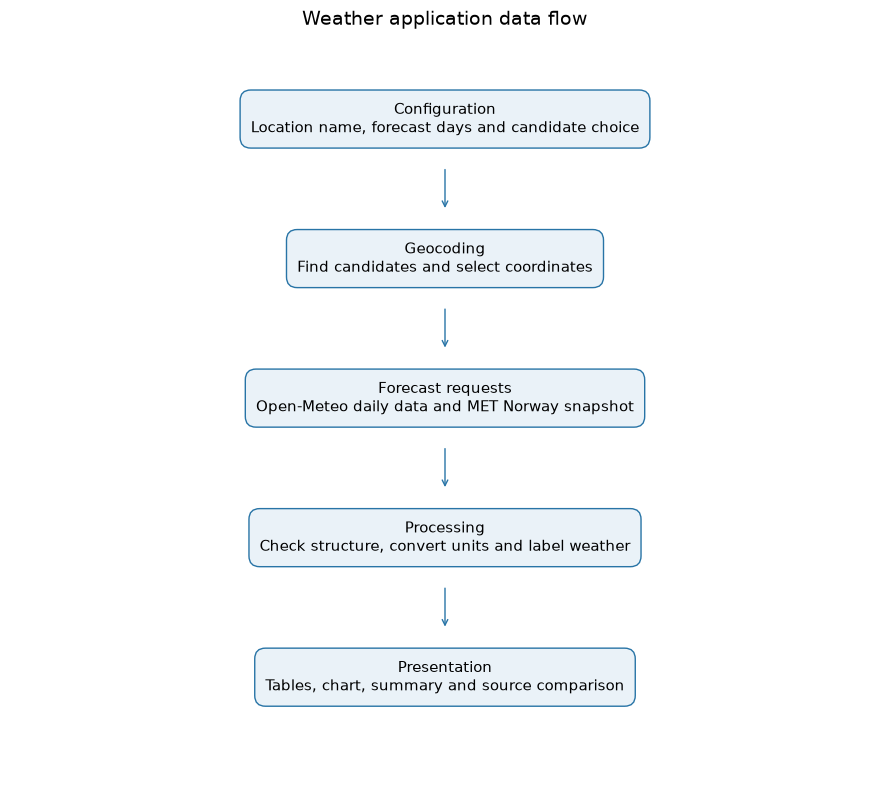

In [22]:
# Import plotting tools for a simple data-flow diagram.
import matplotlib.pyplot as plt

# Describe the main stages from user settings to displayed results.
stages = [
    "Configuration\nLocation name, forecast days and candidate choice",
    "Geocoding\nFind candidates and select coordinates",
    "Forecast requests\nOpen-Meteo daily data and MET Norway snapshot",
    "Processing\nCheck structure, convert units and label weather",
    "Presentation\nTables, chart, summary and source comparison"
]

# Position each stage in a vertical flow.
fig, axis = plt.subplots(figsize=(9, 8))
axis.set_xlim(0, 1)
axis.set_ylim(0, 1)
axis.axis("off")

positions = [0.90, 0.71, 0.52, 0.33, 0.14]

# Draw labelled boxes and arrows showing the direction of data flow.
for index, (stage, position) in enumerate(zip(stages, positions)):
    axis.text(
        0.5,
        position,
        stage,
        ha="center",
        va="center",
        fontsize=11,
        bbox={
            "boxstyle": "round,pad=0.7",
            "facecolor": "#EAF2F8",
            "edgecolor": "#2874A6"
        }
    )

    if index < len(positions) - 1:
        axis.annotate(
            "",
            xy=(0.5, positions[index + 1] + 0.065),
            xytext=(0.5, position - 0.065),
            arrowprops={"arrowstyle": "->", "color": "#2874A6"}
        )

# Give the diagram a clear title.
axis.set_title("Weather application data flow", fontsize=14, pad=15)
fig.tight_layout()
plt.show()

### 3. Licensing and API usage

The provider documentation was checked on 10 October 2026.
Data licences and hosted-service conditions must be considered
separately: permission to reuse data does not imply unlimited
access to the servers providing it.

Open-Meteo supplies API data under Creative Commons Attribution
4.0 International (CC BY 4.0). Reuse requires appropriate credit,
a licence link and an indication of modifications. The geocoding
output also acknowledges GeoNames, the underlying location-data
source. Our tables and charts transform the responses through
formatting, weather-code interpretation and summarisation.

Open-Meteo's free hosted API is for non-commercial use and has
request limits. This educational project uses only a small number
of requests. A commercial application would need an appropriate
commercial service arrangement rather than assuming that the
free endpoint permits commercial use. Data accuracy and continuous
availability are not guaranteed.

MET Norway's licensing page lists NLOD 2.0 and CC BY 4.0 for its
data unless otherwise specified. This project credits MET Norway
and links to CC BY 4.0. Its displayed data are modified through
time-zone conversion, wind-unit conversion and aggregation of
available temperature samples.

MET Norway requires an identifying User-Agent and discourages
unnecessary traffic. The function limits coordinates to four
decimal places and saves a response for reuse. This is a fixed
educational snapshot, not a cache that automatically refreshes.
A production service should respect the Expires response header
and use Last-Modified with conditional requests when refreshing.

For a real product, I would retain visible attribution, identify
stale forecasts, monitor service failures and review the providers'
current terms before deployment. Neither an open licence nor
agreement between providers guarantees that a forecast is correct.

References:
- Open-Meteo licence: https://open-meteo.com/en/licence
- Open-Meteo terms: https://open-meteo.com/en/terms
- MET Norway licensing: https://api.met.no/doc/License
- MET Norway terms: https://api.met.no/doc/TermsOfService
- CC BY 4.0: https://creativecommons.org/licenses/by/4.0/

### 4. Reliability, error handling and testing

The project distinguishes invalid inputs, unsuccessful searches,
network problems and malformed responses. Empty location names
and out-of-range coordinates are rejected before a request is sent.
A location search with no matches returns an empty list, allowing
the notebook to explain that a different query is needed.

The reusable request function sets a timeout and calls
raise_for_status. Connection failures, timeouts and HTTP 5xx errors
allow up to three attempts, with delays of one and two seconds.
Other HTTP errors stop immediately rather than repeatedly sending
a rejected request. Invalid JSON also raises a clear WeatherError.
Exception chaining preserves the underlying cause for diagnosis.

The deliberately nonexistent city returned no matches, while
latitude 100 was rejected locally. A simulated connection failure
confirmed three attempts and the planned retry delays. A live
request with a 0.001-second timeout produced ConnectTimeout.
This timeout result depends on network conditions; the simulation
provides a repeatable check of the retry behaviour.

The initial urllib and requests examples demonstrate HTTP
fundamentals separately from the reusable retry function. These
introductory examples do not yet provide the same retry handling.
Live retrieval also remains dependent on internet access and
provider availability; offline tests do not make the whole
notebook capable of running offline.

The forecast parser checks that required daily fields are lists,
that dates are present and that the lists have equal lengths.
It does not yet validate every measurement's type, range or
physical consistency. This is a limitation to address before
using the parser with untrusted or unexpected data.

Six automated tests passed using a saved forecast response.
They cover preservation of dates and temperatures, weather-code
descriptions, a missing daily section, a missing measurement field,
unequal list lengths and an empty forecast. These checks run
without internet access. They support the cases tested, but do
not prove complete correctness or forecast accuracy.

An additional issue was pandas requiring Jinja2 for styled tables.
Installing it resolved the display error. Jinja2 supports table
rendering; pathlib supports portable paths, and unittest.mock
supports controlled failure simulations.

### 5. Privacy implications

A location lookup sends the entered place name to Open-Meteo.
Forecast requests send coordinates to the chosen provider.
The provider also receives the connection's IP address and the
identifying User-Agent, which contains my university contact email.
HTTPS protects data in transit, but does not hide it from the
service receiving the request.

A city-level query is generally less revealing than a precise home
address or a person's travel history. However, repeated queries
could still reveal interests or movement patterns. Open-Meteo's
privacy terms describe technical logging that may include
coordinates. MET Norway also describes logging IP addresses and
requested coordinates. Users should therefore understand that
location queries leave their own computer.

The project reads the contact email from an environment variable
rather than embedding it in shared source code. It does not print
the email or deliberately save request headers in the JSON samples.
This reduces accidental disclosure through GitHub, although it
does not encrypt the locally stored environment variable.

For a public application, I would explain which providers receive
location data, request only the precision needed and avoid
unnecessary retention of searches. Saved samples and notebook
outputs should be reviewed before publication because they can
contain selected locations. A backend proxy can reduce direct
exposure of users' IP addresses to providers, but creates its own
responsibilities for secure handling and logging.

### 6. Conclusion

The project demonstrates direct HTTP requests, location selection,
forecast parsing, visualisation and controlled error handling.
The recorded Kampala forecast covered five days, with temperatures
ranging from 17.9°C to 27.2°C. These are snapshot results and may
change when the notebook retrieves a newer forecast.

The second source highlights the importance of matching units,
time zones and time coverage before comparing values. Future
improvements would include stronger measurement validation,
automated tests for MET Norway parsing and provider-aware cache
refreshing. Observed weather would be needed to evaluate actual
forecast accuracy.

In [25]:
# Import tools for reading the saved notebook (my report) and counting words.
import json
import re

# Read the notebook file saved on disk.
notebook_path = project_folder / "notebooks" / "project1_weather.ipynb"

with notebook_path.open("r", encoding="utf-8") as file:
    saved_notebook = json.load(file)

# Collect only Markdown cells belonging to Part D.
report_sections = []
inside_report = False

for cell in saved_notebook["cells"]:
    if cell["cell_type"] != "markdown":
        continue

    text = "".join(cell["source"])

    if text.lstrip().startswith("## Part D: Report"):
        inside_report = True

    if inside_report:
        report_sections.append(text)

# Count whitespace-separated words, excluding reference-list entries.
report_text = "\n".join(report_sections)
report_text = re.sub(
    r"^References:\s*$|^- .*https?://.*$",
    "",
    report_text,
    flags=re.MULTILINE
)
word_count = len(report_text.split())

print("Approximate report word count:", word_count)
print("Within 1,000–1,500 words:", 1000 <= word_count <= 1500)

Approximate report word count: 1233
Within 1,000–1,500 words: True
